In [4]:
library(tidyverse)
library(data.table)
library(GenomicRanges)
library(Matrix)
library(VennDiagram)

library('Cairo')
CairoFonts(
regular="Sans:style=Medium",
bold="Sans:style=Bold",
italic="Sans:style=Oblique",
bolditalic="Sans:style=BoldOblique"
)

Warning message in system("timedatectl", intern = TRUE):
“running command 'timedatectl' had status 1”
── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 1.3.1 ──

✔ ggplot2 3.3.5     ✔ purrr   0.3.4
✔ tibble  3.3.0     ✔ dplyr   1.1.4
✔ tidyr   1.1.4     ✔ stringr 1.4.1
✔ readr   2.1.1     ✔ forcats 1.0.0

Warning message:
“package ‘stringr’ was built under R version 4.1.3”
Warning message:
“package ‘forcats’ was built under R version 4.1.3”
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()

Warning message:
“package ‘data.table’ was built under R version 4.1.3”

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose


Warn

In [5]:
work_dir <- "/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/"
setwd(work_dir)

In [6]:
peak_info <- read_tsv(paste0(work_dir, "all_peaks_info.txt"))

Rows: 82350 Columns: 17
── Column specification ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (6): GroupReplicate, nearestGene, peakType, nearestTSS, name, chr
dbl (11): score, replicateScoreQuantile, groupScoreQuantile, Reproducibility...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [7]:
nrow(peak_info)

[1] 82350

In [8]:
head(peak_info)

score,replicateScoreQuantile,groupScoreQuantile,Reproducibility,GroupReplicate,distToGeneStart,nearestGene,peakType,distToTSS,nearestTSS,GC,idx,N,name,chr,start,end
<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
11.66960,0.772,0.745,1,RUNX2._.Rep2,2,LINC00115,Promoter,2,uc010nxx.3,0.6926,1,0,chr1:827269-827769,chr1,827269,827769
6.11759,0.365,0.414,1,CEBPD._.Rep2,18358,LINC00115,Intronic,5466,uc057axk.1,0.4331,2,0,chr1:845631-846131,chr1,845631,846131
8.10241,0.600,0.540,1,FOXO3._.Rep2,18768,FAM41C,Exonic,6785,uc057axk.1,0.3792,3,0,chr1:857884-858384,chr1,857884,858384
11.88400,0.836,0.830,2,FOXO3._.Rep1,6958,FAM41C,Intronic,256,uc057axl.1,0.7405,4,0,chr1:869694-870194,chr1,869694,870194
8.00551,0.578,0.526,2,PRDM1._.Rep2,14967,LINC02593,Distal,109,uc057axn.1,0.7445,5,0,chr1:904474-904974,chr1,904474,904974
4.69594,0.133,0.128,1,RUNX2._.Rep1,6662,LINC02593,Distal,1141,uc057axo.1,0.6128,6,0,chr1:912779-913279,chr1,912779,913279


In [9]:
table(peak_info$peakType)


  Distal   Exonic Intronic Promoter 
   24375     9320    33658    14997 

In [10]:
table(peak_info$peakType, peak_info$Reproducibility)

          
               1     2
  Distal   20734  3641
  Exonic    6394  2926
  Intronic 27839  5819
  Promoter  7268  7729

In [11]:
## Overlap with other datasets

In [12]:
## Read peaks
peaks_gr <- GRanges(seqnames = peak_info$chr,
                    ranges = IRanges(start=peak_info$start, end=peak_info$end),
                    peak = peak_info$name)

## Read ENCODE peaks
encode_bed <- read_tsv('/nfs/casm/team215mg/users/od5/resources/encode_cres_v3/GRCh38-cCREs.bed', col_names=F)
encode_gr <- GRanges(seqnames = encode_bed$X1,
                    ranges = IRanges(start=encode_bed$X2, end=encode_bed$X3),
                    peak = encode_bed$X4,
                    peak_class = encode_bed$X6)

Rows: 1063878 Columns: 6
── Column specification ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
chr (4): X1, X4, X5, X6
dbl (2): X2, X3

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [13]:
## Overlap

peak_overlaps <- findOverlaps(peaks_gr, encode_gr)
peak_overlaps_df <- data.frame(
    peak=peaks_gr$peak[queryHits(peak_overlaps)],
    encode=encode_gr$peak[subjectHits(peak_overlaps)],
    encode_class=encode_gr$peak_class[subjectHits(peak_overlaps)]
)

head(peak_overlaps_df)

,peak,encode,encode_class
,<chr>,<chr>,<chr>
1,chr1:827269-827769,EH38D4327609,"PLS,CTCF-bound"
2,chr1:845631-846131,EH38D2115358,dELS
3,chr1:869694-870194,EH38D4327653,"DNase-H3K4me3,CTCF-bound"
4,chr1:869694-870194,EH38D2115380,"PLS,CTCF-bound"
5,chr1:904474-904974,EH38D4327690,"pELS,CTCF-bound"
6,chr1:904474-904974,EH38D4327691,"PLS,CTCF-bound"


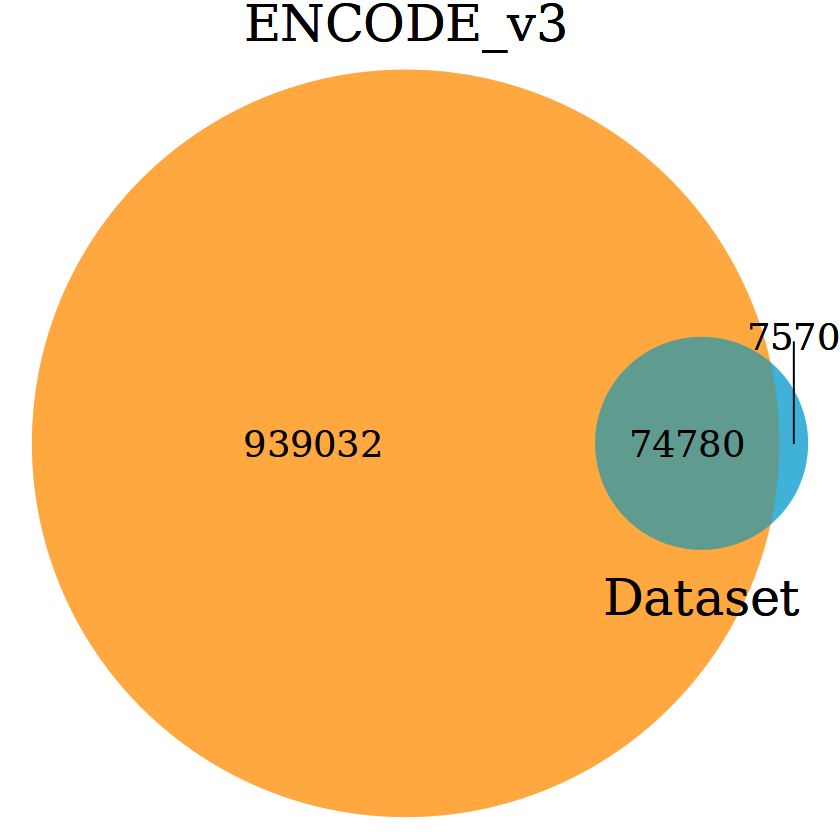

In [14]:
## Plot overlaps
shared <- min(sum(peaks_gr$peak %in% peak_overlaps_df$peak), sum(encode_gr$peak %in% peak_overlaps_df$encode))
dataset_uniq <- sum(!(peaks_gr$peak %in% peak_overlaps_df$peak))
encode_uniq <- sum(!(encode_gr$peak %in% peak_overlaps_df$encode))

## Make VennDiagram
venn.plot <- draw.pairwise.venn(
	area1 = (shared+dataset_uniq),
	area2 = (shared+encode_uniq),
	cross.area = shared,
	category = c("Dataset", "ENCODE_v3"),
	cat.pos = c(0, 180),
	euler.d = TRUE,
	sep.dist = 0.03,
    cex = 1.8,
	cat.cex = 2.5,
    fill = c("deepskyblue3", "darkorange"),
	lty = "blank"
	)
    
grid.draw(venn.plot)

In [15]:
peak_info$in_encode <- peak_info$name %in% peak_overlaps_df$peak

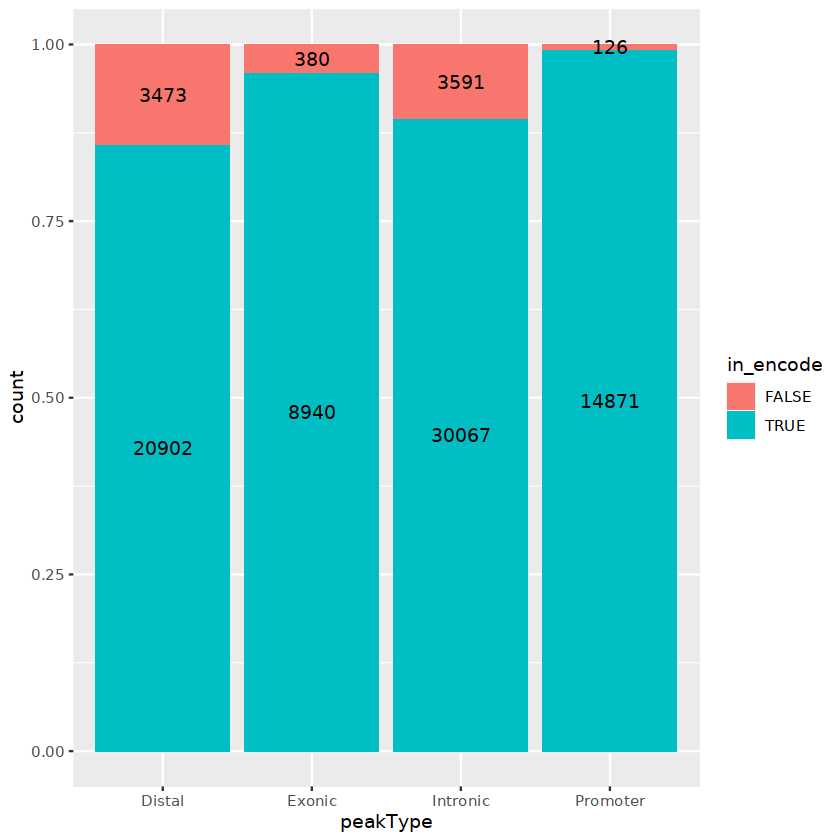

In [16]:
ggplot(peak_info, aes(peakType, fill=in_encode)) + 
geom_bar(position = 'fill') +
geom_text(stat='count',aes(label=..count..), position = position_fill(vjust = 0.5))

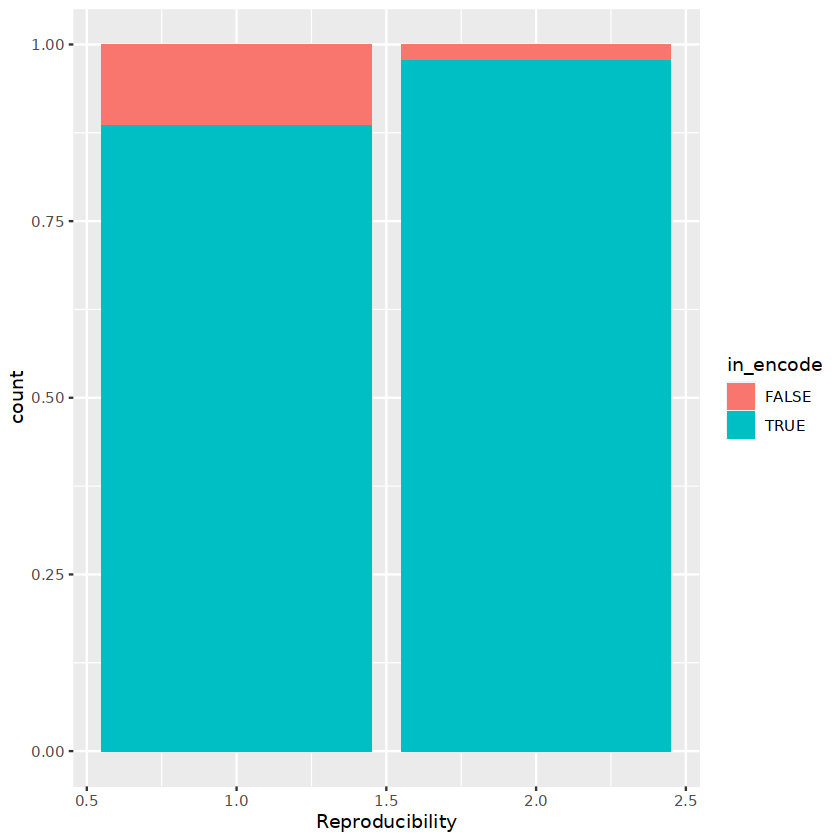

In [17]:
ggplot(peak_info, aes(Reproducibility, fill=in_encode)) + 
geom_bar(position = 'fill')

In [18]:
## Making a cistarget database:
## Putting together dataset peaks and remaining ENCODE peaks
peaks_bed <- dplyr::select(peak_info, chr, start, end, name) %>%
dplyr::rename(X1=chr, X2=start, X3=end, X4=name)

merged_peaks <- bind_rows(
    peaks_bed, 
    encode_bed[!(encode_bed$X4 %in% peak_overlaps_df$encode),]
) %>%
dplyr::select(X1, X2, X3, X4) %>%
arrange(X1, X2)

print(nrow(peaks_bed))
print(nrow(encode_bed))
print(nrow(merged_peaks))

## To confirm, we can also ask what fraction of the genomic space is covered by our peaks
print(sum(peaks_bed$X3 - peaks_bed$X2))
print(sum(encode_bed$X3 - encode_bed$X2))
print(sum(merged_peaks$X3 - merged_peaks$X2))

options(scipen=999)
## Export the merged peak set, as well as the overlap stats
write.table(merged_peaks, paste0(work_dir, 'all_peaks_plus_encode.bed'), col.names = F, row.names = F, quote = F, sep='\t')
write_tsv(peak_overlaps_df, paste0(work_dir, 'peaks_overlap_with_encode_v3.txt'))

[1] 82350
[1] 1063878
[1] 1021382
[1] 41175000
[1] 290119782
[1] 296859809


In [19]:
## And convert to fasta
genome <- '/nfs/casm/team215mg/users/od5/resources/ucsc_genomes/hg38.fa'
system(paste0('bedtools getfasta -fi ' , genome , ' -bed ' , work_dir , 'all_peaks_plus_encode.bed > ' , work_dir , 'all_peaks_plus_encode.fa'))
paste0('bedtools getfasta -fi ' , genome , ' -bed ' , work_dir , 'all_peaks_plus_encode.bed > ' , work_dir , 'all_peaks_plus_encode.fa')

[1] "bedtools getfasta -fi /nfs/casm/team215mg/users/od5/resources/ucsc_genomes/hg38.fa -bed /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/all_peaks_plus_encode.bed > /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/all_peaks_plus_encode.fa"

In [20]:
## Read info about % accessible by cell type
f_access <- read_csv(paste0(work_dir, "archr_peaks_f_access_by_cellType.csv")) %>%
dplyr::rename(name = `...1`)

New names:
• `` -> `...1`
Rows: 82350 Columns: 11
── Column specification ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ...1
dbl (10): HOPX, TCF7, CEBPD, RUNX2, FOXO3, EBF1, TBX21, Control, PRDM1, CEBPA

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [21]:
## Check that peaks are in correct order
sum(peak_info$name == f_access$name) == nrow(peak_info)

[1] TRUE

In [22]:
f_access

name,HOPX,TCF7,CEBPD,RUNX2,FOXO3,EBF1,TBX21,Control,PRDM1,CEBPA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1:827269-827769,0.042577675,0.046755725,0.041152263,0.063829787,0.045138889,0.067375887,0.062500000,0.051401869,0.027118644,0.0000000
chr1:845631-846131,0.019562716,0.013358779,0.037037037,0.003039514,0.013888889,0.017730496,0.020833333,0.015186916,0.023728814,0.0000000
chr1:857884-858384,0.003452244,0.003816794,0.004115226,0.003039514,0.008680556,0.000000000,0.005208333,0.001168224,0.003389831,0.0000000
chr1:869694-870194,0.039700806,0.032442748,0.039094650,0.063829787,0.041666667,0.049645390,0.060763889,0.040887850,0.023728814,0.0000000
chr1:904474-904974,0.055235903,0.046755725,0.043209877,0.042553191,0.055555556,0.067375887,0.046875000,0.061915888,0.047457627,0.0000000
chr1:912779-913279,0.027042578,0.023854962,0.032921811,0.039513678,0.026041667,0.024822695,0.027777778,0.028037383,0.023728814,0.0000000
chr1:921025-921525,0.034522440,0.043893130,0.032921811,0.036474164,0.026041667,0.046099291,0.048611111,0.042056075,0.037288136,0.1666667
chr1:923604-924104,0.039700806,0.032442748,0.039094650,0.066869301,0.043402778,0.053191489,0.045138889,0.053738318,0.037288136,0.0000000
chr1:924624-925124,0.042577675,0.035305344,0.047325103,0.030395137,0.052083333,0.056737589,0.043402778,0.033878505,0.037288136,0.0000000


In [23]:
## Add info about maximum accessibility across cell types
peak_info$max_f_access <- apply(f_access[,2:ncol(f_access)], 1, max)

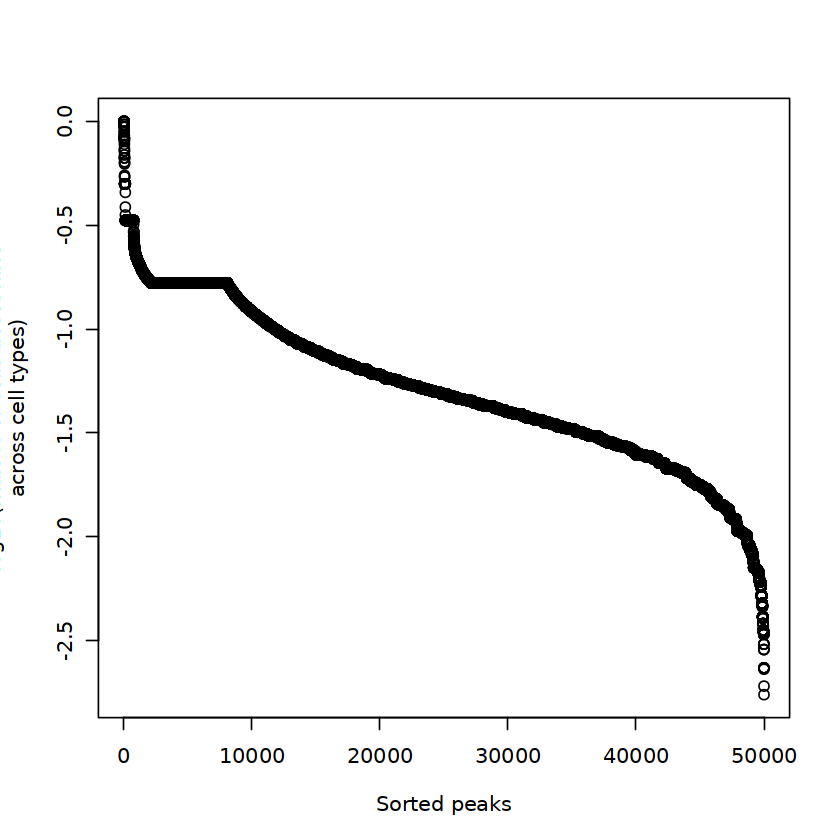

In [24]:
## The optimal fraction of accessible cells depends on each dataset (e.g., sequencing depth)
## Looking into the distribution to understand which cutoff makes most sense:
plot(sort(log10(peak_info$max_f_access[sample(1:nrow(peak_info), 5e4)]), decreasing = T),
     ylab='log10(max % of cells accessible\nacross cell types)', 
    xlab='Sorted peaks')

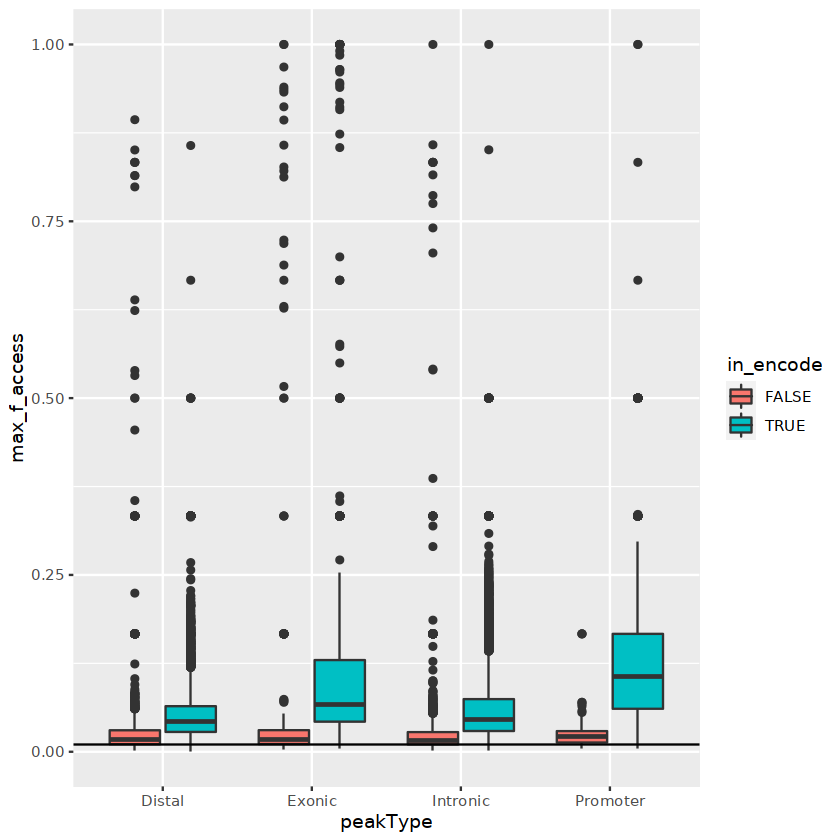

In [25]:
## 0.01 seems like an appropriate cutoff
ggplot(peak_info, aes(x=peakType, fill=in_encode, y=max_f_access)) + 
geom_boxplot() +
geom_hline(yintercept = 0.01)

In [26]:
table(peak_info$max_f_access > 0.01)


FALSE  TRUE 
 2157 80193 

In [27]:
peak_info$robust <- peak_info$max_f_access > 0.01

In [28]:
colnames(f_access)

[1] "name"    "HOPX"    "TCF7"    "CEBPD"   "RUNX2"   "FOXO3"   "EBF1"   
 [8] "TBX21"   "Control" "PRDM1"   "CEBPA"

In [29]:
## Overlap with DARs
markerPeaks_df <- read_tsv(paste0(work_dir, 'archr_DARs_perturbation_df.txt'))

Rows: 754 Columns: 8
── Column specification ───────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): chr, Cell_type, peak
dbl (5): start, end, Log2FC, FDR, MeanDiff

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [30]:
head(markerPeaks_df)

chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
chr7,76054083,76054583,6.712435,0.005603769452,0.2984721,CEBPD,chr7:76054083-76054583
chr1,33099239,33099739,4.986931,0.000003334459,0.6204648,RUNX2,chr1:33099239-33099739
chr1,24964880,24965380,5.319872,0.000004743871,0.4516259,RUNX2,chr1:24964880-24965380
chr1,224623733,224624233,6.728430,0.000012159796,0.4287242,RUNX2,chr1:224623733-224624233
chr4,139950552,139951052,6.327037,0.000012159796,0.3236074,RUNX2,chr4:139950552-139951052
chr5,123180084,123180584,6.978755,0.000012159796,0.5107302,RUNX2,chr5:123180084-123180584


In [31]:
markerPeaks_df$in_encode <- markerPeaks_df$peak %in% peak_info$name[peak_info$in_encode]

In [32]:
dar_cell_type_counts <- group_by(markerPeaks_df, Cell_type) %>%
dplyr::count()

In [33]:
summary(dar_cell_type_counts$n)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    1.0     2.0     3.0   251.3   376.5   750.0 

In [34]:
sum(dar_cell_type_counts$n < 100)

[1] 2

In [35]:
table(markerPeaks_df$in_encode)


FALSE  TRUE 
   98   656 

In [36]:
# ## Also load cell type hierarchy
# cell_hierarchy  <- read_csv('/nfs/team205/is10/projects/thygenereg/metadata/anno_v2_nuc_gex_hierarchy.csv') %>%
# dplyr::rename(Cell_type= level_4)

In [37]:
head(cell_hierarchy)

ERROR: Error in h(simpleError(msg, call)): error in evaluating the argument 'x' in selecting a method for function 'head': object 'cell_hierarchy' not found


In [38]:
# markerPeaks_df <- left_join(markerPeaks_df, cell_hierarchy)

In [39]:
nrow(markerPeaks_df)

[1] 754

In [40]:
length(unique(markerPeaks_df$peak))

[1] 754

In [41]:
options(repr.plot.width=12, repr.plot.height=5)
cell_types_with_dars <- dar_cell_type_counts$Cell_type[dar_cell_type_counts$n >= 100]

ggplot(filter(markerPeaks_df, Cell_type %in% cell_types_with_dars), aes(Cell_type, fill=in_encode)) + 
    geom_bar(position='fill') +
    facet_grid(.~level_0,  scales='free_x', space='free_x') + 
    theme(axis.text.x=element_text(angle=90, hjust = 1, vjust=0.5), 
         strip.text = element_text(angle = 90, hjust = 0, vjust = 0.5))

ERROR while rich displaying an object: Error in `combine_vars()`:
! At least one layer must contain all faceting variables: `level_0`.
* Plot is missing `level_0`
* Layer 1 is missing `level_0`

Traceback:
1. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
2. tryCatchList(expr, classes, parentenv, handlers)
3. tryCatchOne(expr, names, parentenv, handlers[[1L]])
4. doTryCatch(return(expr), name, parentenv, handler)
5. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = e

In [42]:
write_tsv(peak_info, paste0(work_dir, "all_peaks_info.txt"))

In [43]:
sessionInfo()

R version 4.1.2 (2021-11-01)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /software/conda/users/od5/archr/lib/libopenblasp-r0.3.28.so

locale:
 [1] LC_CTYPE=en_GB.utf8       LC_NUMERIC=C             
 [3] LC_TIME=en_GB.utf8        LC_COLLATE=en_GB.utf8    
 [5] LC_MONETARY=en_GB.utf8    LC_MESSAGES=en_GB.utf8   
 [7] LC_PAPER=en_GB.utf8       LC_NAME=C                
 [9] LC_ADDRESS=C              LC_TELEPHONE=C           
[11] LC_MEASUREMENT=en_GB.utf8 LC_IDENTIFICATION=C      

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] Cairo_1.6-2          VennDiagram_1.7.3    futile.logger_1.4.3 
 [4] Matrix_1.5-4.1       GenomicRanges_1.46.1 GenomeInfoDb_1.30.1 
 [7] IRanges_2.28.0       S4Vectors_0.32.4     BiocGenerics_0.40.0 
[10] data.table_1.14.8    forcats_1.0.0        stringr_1.4.1       
[13] dplyr_1.1.4        